# §5.7 — Modelo substituto (Tabelas 27–33, Figuras 41–58, Apêndices B e C)

Três redes, uma por trecho do sistema offshore da §5.5 (Tabela 21), com o fluido da Tabela 6 e o modelo
de não escorregamento: entradas (P_in, T_in, m), saídas (P_out, T_out). Massa de dados de
`surrogate.pipeline` em `runs/surrogate/`: 300 amostras próprias por trecho (hipercubo latino nas faixas
das Tabelas 27–29) e as 299 entradas do Apêndice B simuladas pelo cmfsim; grelha de 135 redes
(Apêndice C); modelos finais com os hiperparâmetros da Tabela 31 em `models/surrogate/`; corrida de
referência do sistema completo (Figuras 57–58). Figuras 45–58 digitalizadas sobrepostas. Não simula.

In [1]:
import csv
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[2] if "__file__" in globals() else Path.cwd()))

import numpy as np

from dissertation.notebook_utils import DATA, ROOT, RUNS, figure, plt, save, table

from cmfsim import load_run
from surrogate.dataset import load_dataset
from surrogate.model import MLP
from surrogate.predict import chain_predict
from surrogate.train import r2_score

SEG = {"well": "poço", "line": "linha de escoamento", "riser": "riser"}
SR = RUNS / "surrogate"
ST = json.load(open(DATA / "surrogate_tables.json"))
ds = {s: load_dataset(SR / f"{s}.npz") for s in SEG}
dsb = {s: load_dataset(SR / f"{s}_appendix_b.npz") for s in SEG if (SR / f"{s}_appendix_b.npz").exists()}
appb = {s: np.loadtxt(DATA / f"appendix_b_{s}.csv", delimiter=",", skiprows=1) for s in SEG}
appc = {s: list(csv.DictReader(open(DATA / f"appendix_c_{s}.csv"))) for s in SEG}
grid = {s: list(csv.DictReader(open(SR / f"grid_{s}.csv"))) for s in SEG if (SR / f"grid_{s}.csv").exists()}
models = {s: MLP.load(ROOT / "models" / "surrogate" / f"{s}.json") for s in SEG}
hist = {s: np.load(SR / f"history_{s}.npz") for s in SEG}
ref = load_run(SR / "offshore_table6_noslip.npz")
figs = {n: figure(n) for n in range(45, 59)}
print(
    "amostras válidas por trecho:", {s: int(d["ok"].sum()) for s, d in ds.items()}, "| Apêndice B simulado:", list(dsb)
)


def test_split(s):
    """Índices de teste e de treino usados no modelo final (gravados com o histórico)."""
    return hist[s]["test_idx"], hist[s]["train_idx"]

amostras válidas por trecho: {'well': 300, 'line': 300, 'riser': 300} | Apêndice B simulado: ['well', 'line', 'riser']


## Tabelas 27–29 e Figuras 41–43 — faixas e amostras

Faixas da dissertação e as 300 amostras próprias (hipercubo latino, semente 0) contra as 299 do
Apêndice B (o autor imprime 299: salta o caso 253 nas três tabelas).

| trecho | Tabela | P_in [bar] | T_in [°C] | m [kg/s] | amostras cmfsim | amostras Apêndice B |
|---|---|---|---|---|---|---|
| poço | 27 | 145–185 | 60–100 | 2–25 | 300 | 299 |
| linha de escoamento | 28 | 60–100 | 50–90 | 2–25 | 300 | 299 |
| riser | 29 | 40–80 | 30–70 | 2–25 | 300 | 299 |
figura: notebooks/figs/nb_5_7_fig41_43.png


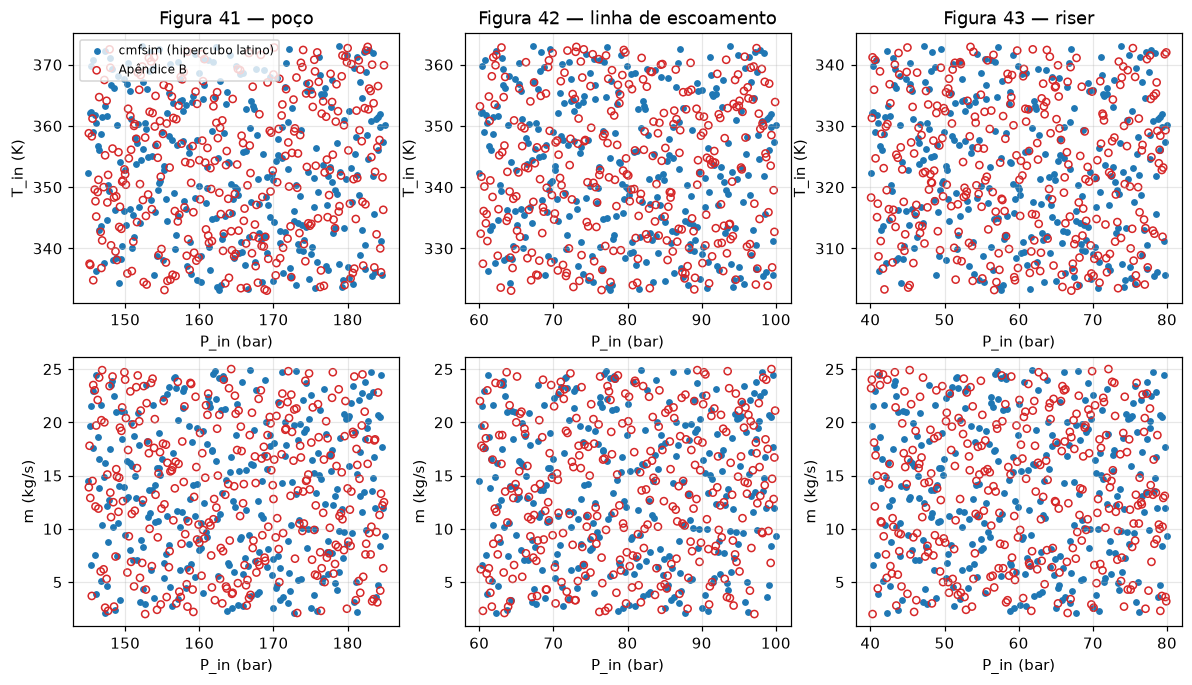

In [2]:
rows = []
for s, name in SEG.items():
    r = ST["ranges"][s]
    rows.append(
        (
            name,
            r["_table"],
            f"{r['P_in_bar'][0]:.0f}–{r['P_in_bar'][1]:.0f}",
            f"{r['T_in_C'][0]:.0f}–{r['T_in_C'][1]:.0f}",
            f"{r['m_kg_s'][0]:.0f}–{r['m_kg_s'][1]:.0f}",
            int(ds[s]["ok"].sum()),
            len(appb[s]),
        )
    )
table(rows, ["trecho", "Tabela", "P_in [bar]", "T_in [°C]", "m [kg/s]", "amostras cmfsim", "amostras Apêndice B"])
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, (s, name) in enumerate(SEG.items()):
    X = ds[s]["X"]
    B = appb[s]
    for i, (yc, yl) in enumerate(((1, "T_in (K)"), (2, "m (kg/s)"))):
        ax = axes[i, j]
        ax.scatter(X[:, 0], X[:, yc], s=12, label="cmfsim (hipercubo latino)")
        ax.scatter(B[:, 1], B[:, 1 + yc], s=22, facecolors="none", edgecolors="tab:red", label="Apêndice B")
        ax.set_xlabel("P_in (bar)")
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if i == 0:
            ax.set_title(f"Figura {41 + j} — {name}")
axes[0, 0].legend(fontsize=8)
save(fig, "nb_5_7_fig41_43")

## Apêndice B — o modelo físico do cmfsim nas entradas do autor

O Apêndice B traz as saídas do modelo físico da dissertação para cada amostra. Simuladas as mesmas
entradas com o cmfsim (mesmo fluido, mesmos trechos), a comparação mede diretamente o modelo de não
escorregamento nos três trechos, sem rede pelo meio.

| trecho | saída | n | R² | desvio médio | desvio abs. médio | erro % médio | desvio máx. |
|---|---|---|---|---|---|---|---|
| poço | P_out | 299 | 0.9790 | +1.35 bar | 1.35 bar | 1.77 % | 3.97 bar |
| poço | T_out | 299 | 0.9963 | -0.07 K | 0.50 K | 0.15 % | 1.73 K |
| linha de escoamento | P_out | 299 | 0.9572 | -1.82 bar | 1.82 bar | 3.23 % | 13.17 bar |
| linha de escoamento | T_out | 299 | 0.3139 | +10.06 K | 10.06 K | 3.26 % | 16.81 K |
| riser | P_out | 299 | 0.9856 | -1.16 bar | 1.16 bar | 2.28 % | 1.76 bar |
| riser | T_out | 299 | 0.9965 | -0.35 K | 0.57 K | 0.18 % | 2.21 K |


figura: notebooks/figs/nb_5_7_appendix_b.png


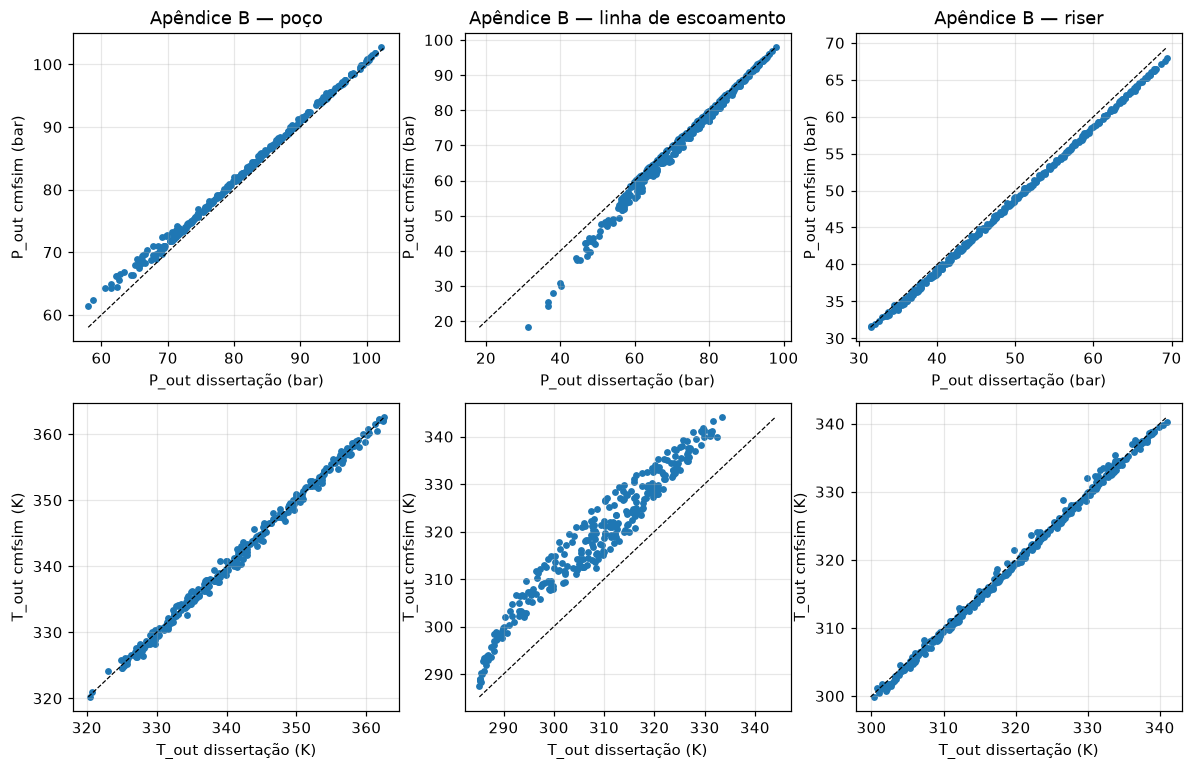

In [3]:
rows = []
for s, name in SEG.items():
    if s not in dsb:
        continue
    d = dsb[s]
    ok = d["ok"]
    Yc, Yb = d["Y"][ok], appb[s][ok, 4:6]
    dev = Yc - Yb
    r2 = r2_score(Yb, Yc)
    for k, (col, unit) in enumerate((("P_out", "bar"), ("T_out", "K"))):
        rows.append(
            (
                name,
                col,
                int(ok.sum()),
                f"{r2[k]:.4f}",
                f"{dev[:, k].mean():+.2f} {unit}",
                f"{np.abs(dev[:, k]).mean():.2f} {unit}",
                f"{(100 * np.abs(dev[:, k]) / np.abs(Yb[:, k])).mean():.2f} %",
                f"{np.abs(dev[:, k]).max():.2f} {unit}",
            )
        )
table(rows, ["trecho", "saída", "n", "R²", "desvio médio", "desvio abs. médio", "erro % médio", "desvio máx."])
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for j, (s, name) in enumerate(SEG.items()):
    if s not in dsb:
        continue
    d = dsb[s]
    ok = d["ok"]
    for i, (col, unit) in enumerate((("P_out", "bar"), ("T_out", "K"))):
        ax = axes[i, j]
        yb, yc = appb[s][ok, 4 + i], d["Y"][ok, i]
        ax.scatter(yb, yc, s=12)
        lo, hi = min(yb.min(), yc.min()), max(yb.max(), yc.max())
        ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
        ax.set_xlabel(f"{col} dissertação ({unit})")
        ax.set_ylabel(f"{col} cmfsim ({unit})")
        ax.grid(alpha=0.3)
        if i == 0:
            ax.set_title(f"Apêndice B — {name}")
save(fig, "nb_5_7_appendix_b")

## Apêndice C e Tabela 30 — busca em grelha (135 redes por trecho)

Mesma grelha e mesma numeração do Apêndice C: camadas {1, 2, 3} × ativação {relu, sigmoid, tanh} ×
neurónios {5, 10, 15, 20, 25} × taxa {0,1, 0,01, 0,001}, todas treinadas com os mesmos dados (70/30,
semente 0, 2000 épocas de Adam em lote completo) e avaliadas pelo R² de teste em P e T
(`surrogate.grid`; CSV completos em `runs/surrogate/grid_*.csv` e `models/surrogate/grid_*.csv`). Os R²
do autor vêm de um treino em PyTorch com inicialização aleatória. Compara-se o número de redes com
R² > 0,9 em P e T, a lista das que o conseguem nos três trechos e as dez melhores de cada trecho.
**Os modelos finais usam os hiperparâmetros da Tabela 31 (reprodução da dissertação), não a melhor rede
da nossa grelha**: com estes dados quase todas as redes ficam acima de 0,99 e a escolha pesa pouco.

**poço: dez melhores redes da grelha (por R² P + R² T no teste)**
| caso | neurónios | taxa | ativação | camadas | R² P cmfsim | R² T cmfsim | R² P / T dissertação |
|---|---|---|---|---|---|---|---|
| 84 | 20 | 0.1 | sigmoid | 1 | 1.0000 | 0.9997 | 0.97 / 0.89 |
| 57 | 15 | 0.1 | sigmoid | 1 | 0.9999 | 0.9996 | 0.97 / 0.89 |
| 112 | 25 | 0.1 | sigmoid | 2 | 0.9998 | 0.9998 | -0.16 / 0.01 |
| 30 | 10 | 0.1 | sigmoid | 1 | 0.9999 | 0.9995 | 0.96 / 0.87 |
| 33 | 10 | 0.1 | tanh | 1 | 0.9999 | 0.9995 | 0.80 / 0.84 |
| 85 | 20 | 0.1 | sigmoid | 2 | 0.9998 | 0.9997 | 0.33 / 0.40 |
| 111 | 25 | 0.1 | sigmoid | 1 | 1.0000 | 0.9995 | 0.97 / 0.85 |
| 70 | 15 | 0.01 | tanh | 2 | 0.9999 | 0.9993 | 0.98 / 0.94 |
| 87 | 20 | 0.1 | tanh | 1 | 0.9999 | 0.9993 | 0.92 / 0.91 |
| 44 | 10 | 0.01 | tanh | 3 | 0.9997 | 0.9994 | 0.98 / 0.92 |
   piores: caso 11 (5n, relu, 3c, taxa 0.01): R² -0.05/-0.00; caso 20 (5n, relu, 3c, taxa 0.001): R² -0.05/-0.00; caso 22 (5n, sigmoid, 2c, taxa 0.001): R² 0.95/0.93; 

figura: notebooks/figs/nb_5_7_appendix_c.png


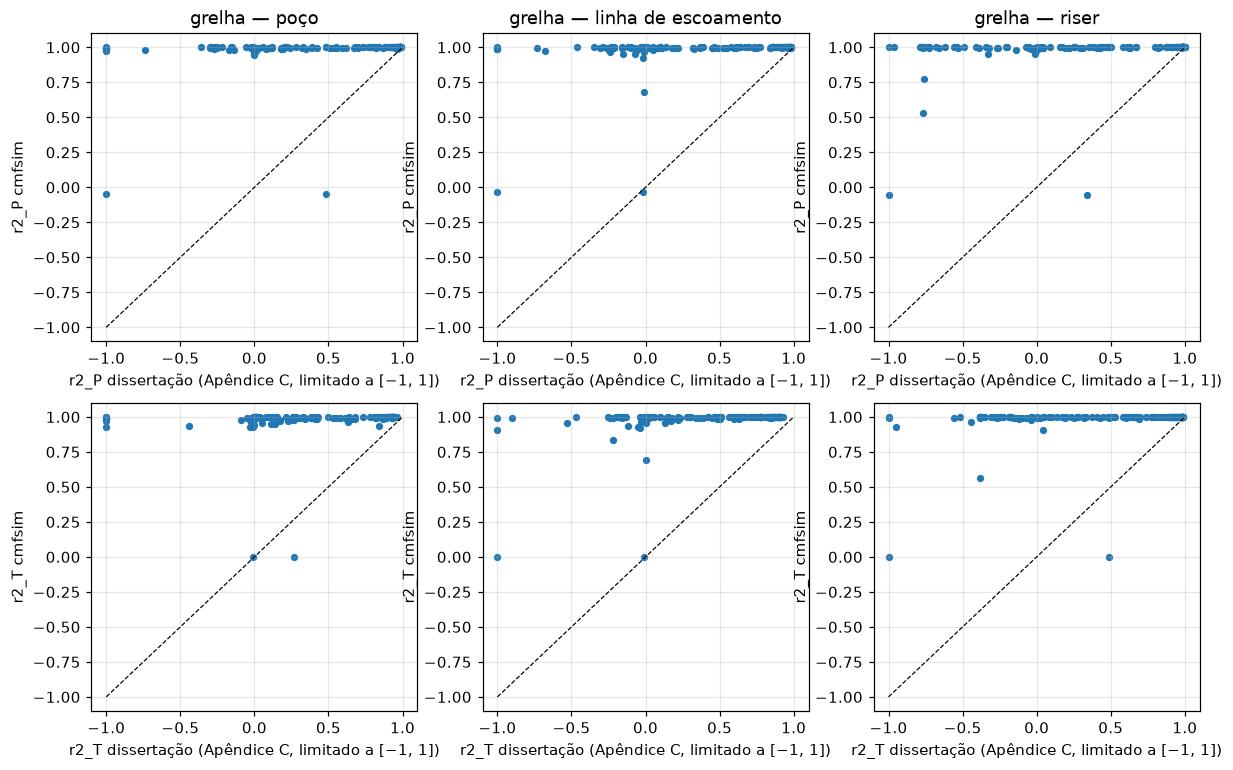

In [4]:
if grid:
    for s, name in SEG.items():
        ranked = sorted(grid[s], key=lambda r: -float(r["r2_sum"]))[:10]
        theirs = {r["case"]: r for r in appc[s]}
        rows = [
            (
                r["case"],
                r["neurons"],
                r["learning_rate"],
                r["activation"],
                r["layers"],
                f"{float(r['r2_P']):.4f}",
                f"{float(r['r2_T']):.4f}",
                f"{float(theirs[r['case']]['r2_P']):.2f} / {float(theirs[r['case']]['r2_T']):.2f}",
            )
            for r in ranked
        ]
        print(f"**{name}: dez melhores redes da grelha (por R² P + R² T no teste)**")
        table(rows, ["caso", "neurónios", "taxa", "ativação", "camadas", "R² P cmfsim", "R² T cmfsim", "R² P / T dissertação"])
        worst = sorted(grid[s], key=lambda r: float(r["r2_sum"]))[:4]
        print("   piores:", "; ".join(f"caso {r['case']} ({r['neurons']}n, {r['activation']}, {r['layers']}c, taxa {r['learning_rate']}): R² {float(r['r2_P']):.2f}/{float(r['r2_T']):.2f}" for r in worst))
    rows = []
    for s, name in SEG.items():
        ours = [r for r in grid[s] if r["both_above_0_9"] == "True"]
        theirs = [r for r in appc[s] if r["both_above_0_9"] == "True"]
        both = {r["case"] for r in ours} & {r["case"] for r in theirs}
        rows.append((name, len(ours), len(theirs), len(both)))
    table(rows, ["trecho", "R² > 0,9 em P e T: cmfsim", "dissertação", "em comum"])
    all_ours = set.intersection(*[{r["case"] for r in grid[s] if r["both_above_0_9"] == "True"} for s in SEG])
    all_theirs = {str(r["case"]) for r in ST["table30_all_segments_above_0_9"]}
    print(
        f"redes com R² > 0,9 nos três trechos: cmfsim {len(all_ours)} | Tabela 30 (dissertação) {len(all_theirs)} | em comum {len(all_ours & all_theirs)}"
    )
    rows = []
    for r in ST["table30_all_segments_above_0_9"]:
        c = str(r["case"])
        ours = {s: next(g for g in grid[s] if g["case"] == c) for s in SEG}
        rows.append(
            (
                c,
                r["neurons"],
                r["learning_rate"],
                r["activation"],
                r["layers"],
                f"{r['r2_P']:.2f} / {r['r2_T']:.2f}",
                *[f"{float(ours[s]['r2_P']):.3f} / {float(ours[s]['r2_T']):.3f}" for s in SEG],
            )
        )
    table(
        rows,
        [
            "caso",
            "neurónios",
            "taxa",
            "ativação",
            "camadas",
            "R² P / T Tabela 30",
            "cmfsim poço",
            "cmfsim linha",
            "cmfsim riser",
        ],
    )
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    for j, (s, name) in enumerate(SEG.items()):
        for i, col in enumerate(("r2_P", "r2_T")):
            ax = axes[i, j]
            x = np.array([float(r[col]) for r in appc[s]])
            y = np.array([float(r[col]) for r in grid[s]])
            ax.scatter(np.clip(x, -1, 1), np.clip(y, -1, 1), s=14)
            ax.plot([-1, 1], [-1, 1], "k--", lw=0.8)
            ax.set_xlabel(f"{col} dissertação (Apêndice C, limitado a [−1, 1])")
            ax.set_ylabel(f"{col} cmfsim")
            ax.grid(alpha=0.3)
            if i == 0:
                ax.set_title(f"grelha — {name}")
    save(fig, "nb_5_7_appendix_c")

## Tabelas 31–32 e Figuras 45–56 — modelos finais (1 camada, 20 neurónios, ReLU, taxa 0,01)

Erro quadrático médio padronizado ao longo do treino (Figuras 45, 49, 53), histogramas do erro relativo
absoluto no teste (46, 50, 54) e paridades (47–48, 51–52, 55–56), tudo nas variáveis normalizadas em
[0, 1] como nas figuras da dissertação. O eixo das figuras do autor vai até ~200 «contagens»; o nosso
treino usa épocas de lote completo.

Tabela 31: {'layers': 1, 'neurons': 20, 'activation': 'relu', 'learning_rate': 0.01} | cmfsim: Hyperparameters(neurons=20, layers=1, activation='relu', learning_rate=0.01, epochs=2000, beta1=0.9, beta2=0.999, eps=1e-08)
| trecho | saída | R² Tabela 32 | R² cmfsim (teste) | RMSE | erro % médio | erro abs. máx. | n teste |
|---|---|---|---|---|---|---|---|
| poço | P | 0.983 | 0.9997 | 0.169 | 0.143 % | 0.840 | 90 |
| poço | T | 0.936 | 0.9972 | 0.588 | 0.065 % | 5.026 | 90 |
| linha de escoamento | P | 0.980 | 0.9996 | 0.304 | 0.357 % | 1.009 | 90 |
| linha de escoamento | T | 0.926 | 0.9979 | 0.646 | 0.136 % | 3.546 | 90 |
| riser | P | 0.963 | 0.9999 | 0.112 | 0.148 % | 0.438 | 90 |
| riser | T | 0.905 | 0.9994 | 0.283 | 0.049 % | 2.038 | 90 |
{'well': '122 parâmetros', 'line': '122 parâmetros', 'riser': '122 parâmetros'}


figura: notebooks/figs/nb_5_7_fig45_49_53.png


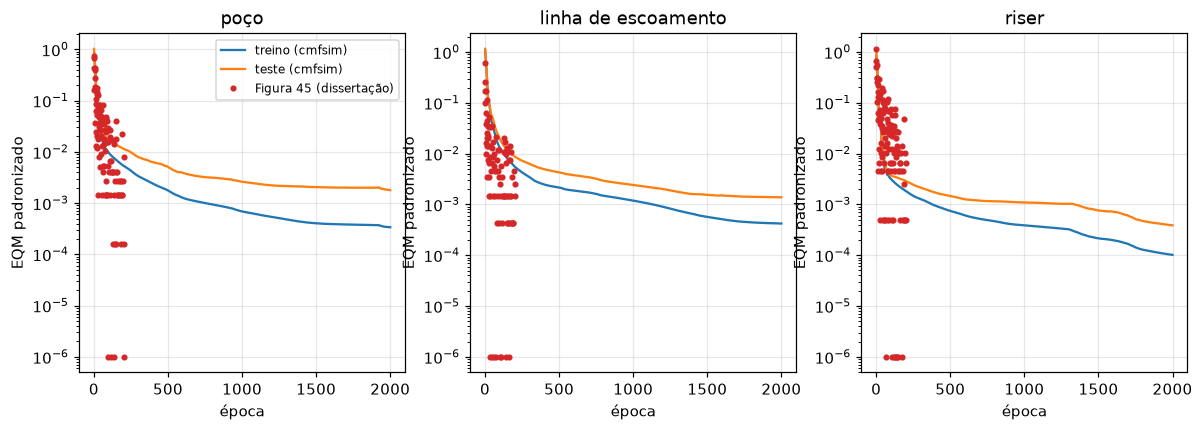

figura: notebooks/figs/nb_5_7_fig46_50_54.png


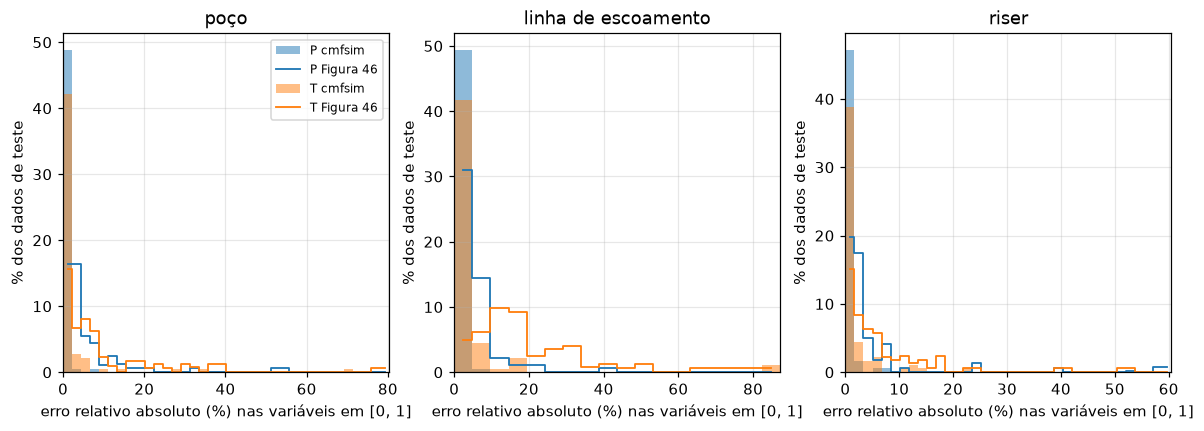

figura: notebooks/figs/nb_5_7_fig47_56.png


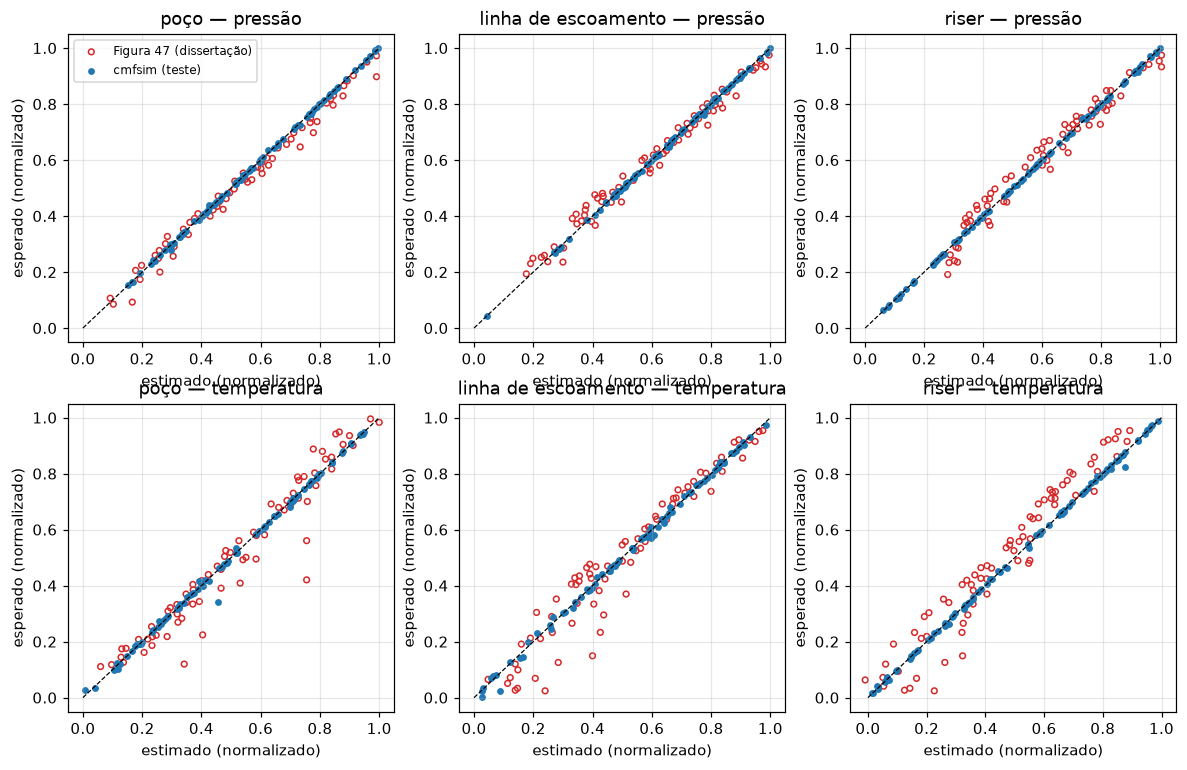

In [5]:
hp = ST["table31_hyperparameters"]
print("Tabela 31:", hp, "| cmfsim:", models["well"].hp)
rows = []
for s, name in SEG.items():
    m = models[s]
    t = m.meta["test"]
    for k, col in enumerate(("P", "T")):
        rows.append(
            (
                name,
                col,
                f"{ST['table32_r2_test'][s][col]:.3f}",
                f"{t['r2'][k]:.4f}",
                f"{t['rmse'][k]:.3f}",
                f"{t['mean_percent_error'][k]:.3f} %",
                f"{t['max_abs_error'][k]:.3f}",
                t["n"],
            )
        )
table(
    rows, ["trecho", "saída", "R² Tabela 32", "R² cmfsim (teste)", "RMSE", "erro % médio", "erro abs. máx.", "n teste"]
)
print({s: f"{m.n_parameters} parâmetros" for s, m in models.items()})

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for j, (s, name) in enumerate(SEG.items()):
    ax = axes[j]
    h = hist[s]["history"]
    ax.semilogy(np.arange(1, len(h) + 1), h[:, 0], label="treino (cmfsim)")
    ax.semilogy(np.arange(1, len(h) + 1), h[:, 1], label="teste (cmfsim)")
    xs, ys = figs[45 + 4 * j]["series"][next(iter(figs[45 + 4 * j]["series"]))]
    ax.semilogy(xs, np.clip(ys, 1e-6, None), "o", ms=3, color="tab:red", label=f"Figura {45 + 4 * j} (dissertação)")
    ax.set_xlabel("época")
    ax.set_ylabel("EQM padronizado")
    ax.set_title(name)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
save(fig, "nb_5_7_fig45_49_53")


def normalized_test(s):
    """Esperado e estimado no teste, normalizados em [0, 1] pelos extremos da massa de dados."""
    te, _ = test_split(s)
    d = ds[s]
    Y, Yp = d["Y"][te], models[s].predict(d["X"][te])
    lo, hi = d["Y"][d["ok"]].min(axis=0), d["Y"][d["ok"]].max(axis=0)
    return (Y - lo) / (hi - lo), (Yp - lo) / (hi - lo)


fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for j, (s, name) in enumerate(SEG.items()):
    ax = axes[j]
    Yn, Ypn = normalized_test(s)
    err = 100 * np.abs(Ypn - Yn) / np.maximum(np.abs(Yn), 1e-9)
    fd = figs[46 + 4 * j]
    bins = np.array([b["left"] for b in fd["raw"]["series"][0]["bins"]] + [fd["raw"]["series"][0]["bins"][-1]["right"]])
    for k, (col, color) in enumerate((("P", "tab:blue"), ("T", "tab:orange"))):
        w = np.full(len(err), 100.0 / err.size)
        ax.hist(np.clip(err[:, k], 0, bins[-1]), bins=bins, weights=w, alpha=0.5, color=color, label=f"{col} cmfsim")
        xs, ys = fd["series"][("Pressão", "Temperatura")[k]]
        ax.step(xs, ys, where="mid", color=color, lw=1.2, label=f"{col} Figura {46 + 4 * j}")
    ax.set_xlabel("erro relativo absoluto (%) nas variáveis em [0, 1]")
    ax.set_ylabel("% dos dados de teste")
    ax.set_title(name)
    ax.set_xlim(0, bins[-1])
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
save(fig, "nb_5_7_fig46_50_54")

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for j, (s, name) in enumerate(SEG.items()):
    Yn, Ypn = normalized_test(s)
    for k, col in enumerate(("pressão", "temperatura")):
        ax = axes[k, j]
        n_fig = 47 + 4 * j + k
        pts = figs[n_fig]["series"][next(key for key in figs[n_fig]["series"] if key.startswith("Pontos"))]
        ax.scatter(pts[0], pts[1], s=14, facecolors="none", edgecolors="tab:red", label=f"Figura {n_fig} (dissertação)")
        ax.scatter(Ypn[:, k], Yn[:, k], s=12, label="cmfsim (teste)")
        ax.plot([0, 1], [0, 1], "k--", lw=0.8)
        ax.set_xlabel("estimado (normalizado)")
        ax.set_ylabel("esperado (normalizado)")
        ax.set_title(f"{name} — {col}")
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
save(fig, "nb_5_7_fig47_56")

## Figuras 57–58 e Tabela 33 — substituto encadeado contra o modelo físico

Poço → linha → riser com 170 bar, 80 °C e 20 kg/s na entrada do poço (vazão lida na legenda das
figuras). «Modelo físico» da dissertação (digitalizado) contra a corrida de referência do cmfsim com
o fluido da Tabela 6; «RNA» da dissertação (4 pontos) contra os nossos três modelos encadeados.

| ponto | x [m] | P físico [bar] | P RNA [bar] | erro P cmfsim | erro P Tabela 33 | T físico [°C] | T RNA [°C] | erro T cmfsim | erro T Tabela 33 |
|---|---|---|---|---|---|---|---|---|---|
| cabeça do poço | 1500 | 84.58 | 84.46 | 0.14 % | 1.0 % | 71.67 | 71.62 | 0.02 % | 0.3 % |
| base do riser | 7500 | 68.70 | 68.53 | 0.25 % | 3.8 % | 56.20 | 55.98 | 0.07 % | 0.3 % |
| chegada à unidade | 7800 | 56.96 | 56.83 | 0.24 % | 4.7 % | 53.62 | 53.37 | 0.08 % | 0.6 % |


figura: notebooks/figs/nb_5_7_fig57_58.png


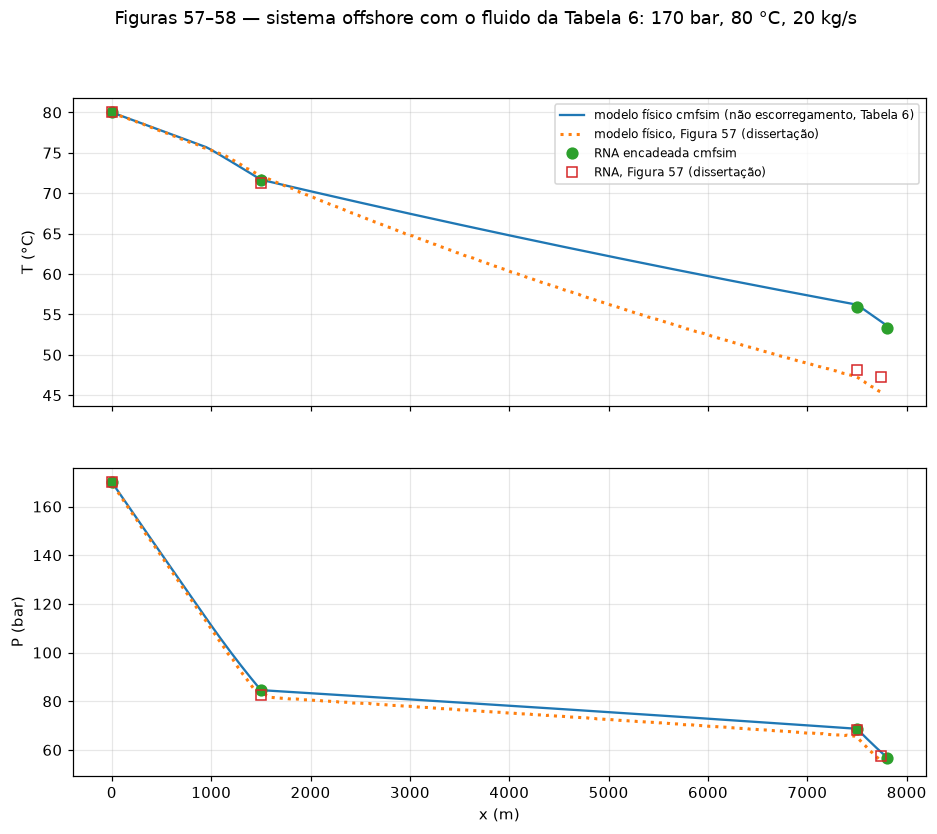

In [6]:
inlet = ref.case_dict["boundary"]["inlet"]
P0, T0, m0 = inlet["P"] / 1e5, inlet["T"], inlet["m"]
chain = chain_predict([models["well"], models["line"], models["riser"]], P0, T0, m0)[:, 0, :]
x_pts = [1500.0, 7500.0, 7800.0]
rows = []
t33 = ST["table33_mean_percent_error_chain"]
for k, (x0, lab) in enumerate(zip(x_pts, ("cabeça do poço", "base do riser", "chegada à unidade"))):
    Pf, Tf = np.interp(x0, ref.x, ref.P) / 1e5, np.interp(x0, ref.x, ref.T)
    Ps, Ts = chain[k]
    key = ("1500", "7500", "7750")[k]
    rows.append(
        (
            lab,
            f"{x0:.0f}",
            f"{Pf:.2f}",
            f"{Ps:.2f}",
            f"{100 * abs(Ps - Pf) / Pf:.2f} %",
            f"{t33['P'][key]:.1f} %",
            f"{Tf - 273.15:.2f}",
            f"{Ts - 273.15:.2f}",
            f"{100 * abs(Ts - Tf) / Tf:.2f} %",
            f"{t33['T'][key]:.1f} %",
        )
    )
table(
    rows,
    [
        "ponto",
        "x [m]",
        "P físico [bar]",
        "P RNA [bar]",
        "erro P cmfsim",
        "erro P Tabela 33",
        "T físico [°C]",
        "T RNA [°C]",
        "erro T cmfsim",
        "erro T Tabela 33",
    ],
)
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for ax, n, y_ref, y_chain, lab in (
    (axes[0], 57, ref.T - 273.15, np.r_[T0, chain[:, 1]] - 273.15, "T (°C)"),
    (axes[1], 58, ref.P / 1e5, np.r_[P0, chain[:, 0]], "P (bar)"),
):
    ax.plot(ref.x, y_ref, label="modelo físico cmfsim (não escorregamento, Tabela 6)")
    ax.plot(*figs[n]["series"]["Modelo físico"], ":", lw=2, label=f"modelo físico, Figura {n} (dissertação)")
    ax.plot([0.0] + x_pts, y_chain, "o", ms=7, label="RNA encadeada cmfsim")
    xs, ys = figs[n]["series"]["RNA"]
    ax.plot(xs, ys, "s", ms=7, mfc="none", color="tab:red", label=f"RNA, Figura {n} (dissertação)")
    ax.set_ylabel(lab)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
axes[1].set_xlabel("x (m)")
fig.suptitle(
    f"Figuras 57–58 — sistema offshore com o fluido da Tabela 6: {P0:.0f} bar, {T0 - 273.15:.0f} °C, {m0:.0f} kg/s"
)
save(fig, "nb_5_7_fig57_58")